In [1]:
# Run from the repo root so relative data/ paths resolve, wherever the notebook is launched.
import os
for _ in range(6):
    if os.path.exists('pyproject.toml'):
        break
    os.chdir('..')


# How the LSTM forecasts beta — a code walkthrough

The pipeline from stock-month panel to out-of-sample beta forecasts lives in
three modules, each with one job:

```
lstm_input_panel.parquet                one row per active stock-month
        |  betaforecast.features.sequences    strict 12-month lookback windows
        v
   X (n, 12, 10), y (n,), meta
        |  betaforecast.features.standardize  leak-free predictor scaling
        v
   model-ready train/val/test folds
        |  betaforecast.model.lstm            walk-forward LSTM ensemble
        v
lstm_oos_forecasts.parquet              one forecast per (stock, month), 2015-2024
```

This notebook runs each stage so you can see its inputs, shapes, and outputs.
Setup: `uv sync`, then `uv run jupyter lab`.

In [2]:
import os
import numpy as np
import pandas as pd

from betaforecast.features import sequences as S
from betaforecast.features import standardize as Z
from betaforecast.model import lstm as M
from betaforecast.paths import REPO

pd.set_option('display.width', 120, 'display.max_columns', 30)
print('predictors :', S.PREDICTORS)
print('lookback L  :', S.L, 'months')
print('target      :', S.TARGET)

predictors : ['OLS_3M_D', 'OLS_1Y_D', 'OLS_5Y_M', 'ME', 'DIVPAY', 'TO', 'MOM', 'IVOL', 'ILLIQ', 'DFY']
lookback L  : 12 months
target      : beta_realized_fwd


## 1. The input panel

Every active-period stock-month with a valid 12-month-forward realized-beta
target and all ten predictors: three OLS betas at different horizons
(`OLS_3M_D`, `OLS_1Y_D`, `OLS_5Y_M`), six firm characteristics (`ME`, `DIVPAY`,
`TO`, `MOM`, `IVOL`, `ILLIQ`), and one macro series (`DFY`). `is_member` flags
SET100 membership — only member-months can be a *forecast origin*, but a
non-member month may still sit inside a lookback window.

In [3]:
df = S.load_panel()            # parses ym to a monthly Period, sorts by (ric, ym)
print('panel rows :', f'{len(df):,}')
print('stocks     :', df['ric'].nunique())
print('months     :', df['ym'].min(), '->', df['ym'].max())
print('member rows:', f"{int(df['is_member'].sum()):,}",
      '| non-member:', f"{int((~df['is_member']).sum()):,}")
df[['ric','ym','is_member', *S.PREDICTORS, S.TARGET]].head()

panel rows : 40,210
stocks     : 277
months     : 2008-04 -> 2024-12
member rows: 17,887 | non-member: 22,323


,ric,ym,is_member,OLS_3M_D,OLS_1Y_D,OLS_5Y_M,ME,DIVPAY,TO,MOM,IVOL,ILLIQ,DFY,beta_realized_fwd
0,A.BK,2008-04,False,0.185550,0.090187,0.212101,7.933596,0.0,1.850239,-0.037719,-5.122017,6.097122e-03,1.42,0.099845
1,A.BK,2008-05,False,0.110111,0.091474,0.211638,7.933596,0.0,2.662984,0.016212,-5.586730,2.280458e-17,1.36,0.111787
2,A.BK,2008-06,False,0.142040,0.094812,0.175705,7.939016,0.0,2.792931,0.033634,-5.903387,3.319343e-04,1.39,0.103113
3,A.BK,2008-07,False,0.071431,0.087925,0.177129,7.911617,0.0,2.422522,-0.009869,-5.815975,2.430207e-03,1.49,0.102038
4,A.BK,2008-08,False,0.061248,0.064817,0.176530,7.906046,0.0,2.461729,-0.041124,-5.223988,4.751420e-04,1.51,0.104877


## 2. Building the lookback sequences

`sequences.build_sequences` keeps a forecast origin `(stock i, month t)` only if
`t` is a member-month **and** the 12 months ending at `t` are contiguous — no
calendar gaps. The gap check is one line: with months sorted and unique, a span
of `L-1` between the first and last ordinal implies `L` consecutive months.
Each survivor becomes a `12 x 10` matrix paired with the beta realized over the
next 12 months.

In [4]:
X, y, meta = S.build_sequences(df)
print('X   :', X.shape, '  (n_sequences, L=12 months, 10 predictors)')
print('y   :', y.shape)
print('meta:', meta.shape, list(meta.columns))
print('origin months span', meta['ym'].min(), '->', meta['ym'].max())

X   : (16285, 12, 10)   (n_sequences, L=12 months, 10 predictors)
y   : (16285,)
meta: (16285, 3) ['ric', 'ym', 'date']
origin months span 2009-03 -> 2024-12


### One sequence up close

The 10 predictors read down the 12 lookback months (raw values, before
standardisation); the target is the forward realized beta.

In [5]:
i = 0                                   # first sequence; change to explore
win = pd.DataFrame(X[i], columns=S.PREDICTORS)
print('origin :', meta.loc[i, 'ric'], meta.loc[i, 'ym'])
print('target : beta_realized_fwd =', round(float(y[i]), 4),
      '(realized over the next 12 months)')
win.round(3)

origin : AAV.BK 2016-04
target : beta_realized_fwd = 0.9738 (realized over the next 12 months)


,OLS_3M_D,OLS_1Y_D,OLS_5Y_M,ME,DIVPAY,TO,MOM,IVOL,ILLIQ,DFY
0,0.773,0.686,2.021,10.034,0.000,6.989,0.138,-4.580,0.0,0.91
1,1.153,0.752,2.024,9.968,0.000,8.379,0.131,-3.787,0.0,0.94
2,1.152,0.673,1.843,10.072,0.000,7.804,0.024,-4.373,0.0,1.05
3,1.185,0.827,1.871,9.955,0.000,8.187,0.052,-3.724,0.0,1.15
4,1.006,0.797,1.824,9.950,0.000,6.896,-0.091,-4.924,0.0,1.27
5,1.083,0.800,1.827,10.017,0.000,6.680,-0.088,-4.870,0.0,1.39
6,0.814,0.803,1.798,10.004,0.000,6.671,0.031,-4.663,0.0,1.40
7,0.678,0.824,1.561,10.145,0.448,7.409,-0.035,-3.942,0.0,1.49
8,0.297,0.718,1.568,10.227,0.448,8.152,0.191,-3.547,0.0,1.45
9,0.134,0.674,1.500,10.116,0.448,7.965,0.036,-3.453,0.0,1.38


## 3. The walk-forward splits

Ten iterations, split by the calendar year of the forecast origin:

| split | years (iteration *k*) | purpose |
|-------|-------|---------|
| train | `2008+k .. 2012+k` (5 yrs, rolling) | fit the LSTM |
| val   | `2013+k` | early stopping |
| **gap** | `2014+k` | **discarded** buffer |
| test  | `2015+k` | out-of-sample forecast |

The gap year equals the 12-month forecast horizon: without it, the validation
labels' realization window would overlap the test window and model selection
would peek ahead (Drobetz et al. 2025).

In [6]:
rows = []
for it in S.walk_forward_iterations():
    tr, va, te = S.split_indices(meta, it)
    rows.append({
        'iter': it['iter'],
        'train_years': f"{it['train_years'][0]}-{it['train_years'][-1]}",
        'val': it['val_year'], 'gap(drop)': it['gap_year'], 'test': it['test_year'],
        'n_train': int(tr.sum()), 'n_val': int(va.sum()), 'n_test': int(te.sum()),
    })
pd.DataFrame(rows)

,iter,train_years,val,gap(drop),test,n_train,n_val,n_test
0,0,2008-2012,2013,2014,2015,3986,1087,987
1,1,2009-2013,2014,2015,2016,5073,1067,966
2,2,2010-2014,2015,2016,2017,5276,987,1004
3,3,2011-2015,2016,2017,2018,5241,966,993
4,4,2012-2016,2017,2018,2019,5164,1004,1032
5,5,2013-2017,2018,2019,2020,5111,993,1024
6,6,2014-2018,2019,2020,2021,5017,1032,1039
7,7,2015-2019,2020,2021,2022,4982,1024,1003
8,8,2016-2020,2021,2022,2023,5019,1039,1027
9,9,2017-2021,2022,2023,2024,5092,1003,1070


## 4. Standardising the predictors — with no look-ahead

Two schemes, both leak-free:

- **Nine firm/beta predictors** — rank-standardised to `[-1, +1]` within each
  month (Gu–Kelly–Xiu). Per-month and self-contained, so it is applied once,
  before sequences are built.
- **DFY (macro)** — min-max scaled with a min/max fit on each iteration's
  **training fold only**, inside the walk-forward loop. Test DFY can fall
  slightly outside `[-1, 1]`; that is expected, not a bug.

In [7]:
Xs, ys, metas = Z.build_model_inputs()      # 9 preds already rank-standardised; DFY still raw
print('rank-standardised predictors (pooled over all sequence cells):')
hdr = f"{'predictor':10s}{'min':>8s}{'max':>8s}{'mean':>8s}"
print(hdr); print('-' * len(hdr))
for p in Z.RANK_PREDICTORS:
    col = Xs[:, :, S.PREDICTORS.index(p)]
    print(f'{p:10s}{col.min():8.2f}{col.max():8.2f}{col.mean():8.2f}')
dfy = Xs[:, :, Z.DFY_IDX]
print(f'\nDFY (raw, scaled later per fold): min {dfy.min():.3f}  max {dfy.max():.3f}')

rank-standardised predictors (pooled over all sequence cells):
predictor      min     max    mean
----------------------------------
OLS_3M_D     -1.00    1.00    0.17
OLS_1Y_D     -1.00    1.00    0.20
OLS_5Y_M     -1.00    1.00    0.04
ME           -0.85    1.00    0.49
DIVPAY       -1.00    1.00    0.09
TO           -1.00    1.00    0.50
MOM          -1.00    1.00    0.09
IVOL         -1.00    1.00   -0.06
ILLIQ        -1.00    1.00   -0.43

DFY (raw, scaled later per fold): min 0.550  max 3.380


### Per-fold assembly

`fold_inputs` slices one iteration's train/val/test and applies the train-fitted
DFY scaling — exactly what the training driver feeds the model.

In [8]:
it0 = S.walk_forward_iterations()[0]
f = Z.fold_inputs(Xs, ys, metas, it0)
print('iteration', f['iter'], '| DFY min-max fit on train:', 
      {k: round(v, 4) for k, v in f['params'].items()})
for split in ['train', 'val', 'test']:
    print(f"  X_{split:5s}: {f['X_'+split].shape}   y_{split:5s}: {f['y_'+split].shape}")

iteration 0 | DFY min-max fit on train: {'min': 0.76, 'max': 3.38}
  X_train: (3986, 12, 10)   y_train: (3986,)
  X_val  : (1087, 12, 10)   y_val  : (1087,)
  X_test : (987, 12, 10)   y_test : (987,)


## 5. The model

A deliberately small network — units and dropout picked by a validation VW-MSE
search over units `{4, 8, 16}` x dropout `{0, 0.1}`, then held fixed everywhere:

```
Input(12, 10)  ->  LSTM(8 units, dropout 0.1)  ->  Dense(1, linear)
```

RMSprop (lr 1e-3), batch 128, up to 1000 epochs with early stopping
(patience 10, best weights restored).

In [9]:
from betaforecast.model import lstm as M
m = M.build_model(seed=0)
m.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 8)              │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 617 (2.41 KB)

 Trainable params: 617 (2.41 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Value-weighted loss

The key subtlety: results are evaluated value-weighted, so training matches.
Each observation is weighted by its within-month market-cap share

$$w_{i,t} = \frac{e^{ME_i}}{\sum_j e^{ME_j}},$$

then the vector is rescaled to mean 1 so the effective learning rate is
unchanged. Passed to Keras as `sample_weight`, this turns the objective into a
value-weighted MSE.

In [10]:
sw = M.value_weights(f['meta_train'])
print('weights:', sw.shape, '| mean =', round(float(sw.mean()), 4), '(rescaled to 1)')
print('min/max:', round(float(sw.min()), 4), '/', round(float(sw.max()), 4),
      ' -> big-cap stock-months pull the loss harder')

# sanity: within any single origin month the raw shares sum to 1
mt = f['meta_train'].copy(); mt['w'] = sw
per_month = mt.groupby('ym')['w'].sum()
print('per-month weight sums (rescaled): mean', round(float(per_month.mean()), 2))

weights: (3986,) | mean = 1.0 (rescaled to 1)
min/max: 0.0126 / 16.0047  -> big-cap stock-months pull the loss harder
per-month weight sums (rescaled): mean 86.65


## 7. The training driver and the ensemble

For each of the 10 iterations, `run_walkforward` builds the fold, trains **10
seeds** (0–9), and averages their test-fold predictions — the ensemble mean
cancels initialisation noise. Forecasts are written after every iteration, so a
crash keeps partial progress.

The full run is `uv run python -m betaforecast.model.lstm` (slow: 100 fits, up
to 1000 epochs each). The cell below is a **mini-demo** of the same loop — 2
seeds, 5 epochs, one fold, nothing written to disk — so the numbers are
illustrative, not the paper's.

In [11]:
RUN_DEMO = False   # set True to train two toy seeds (~a minute on CPU)
if RUN_DEMO:
    seed_preds = []
    for seed in range(2):
        model = M.build_model(seed)
        M.train_model(model, f, max_epochs=5,
                      sw_train=M.value_weights(f['meta_train']),
                      sw_val=M.value_weights(f['meta_val']))
        seed_preds.append(model.predict(f['X_test'], verbose=0).ravel())
    yhat = np.mean(seed_preds, axis=0)          # ensemble = mean over seeds
    print('per-seed test MSE :', [round(float(np.mean((f['y_test']-p)**2)), 4) for p in seed_preds])
    print('ensemble test MSE :', round(float(np.mean((f['y_test']-yhat)**2)), 4))
else:
    print('skipped — set RUN_DEMO = True to watch two seeds train and the ensemble form.')

skipped — set RUN_DEMO = True to watch two seeds train and the ensemble form.


## 8. The out-of-sample forecasts

The full run writes one forecasted beta per stock-month across 2015–2024.
`betaforecast.benchmarks` aligns it with the two rolling-OLS benchmarks into
`oos_forecasts.parquet` — the table every downstream result (VW-MSE,
Diebold–Mariano, importance) is computed from.

In [12]:
oos_path = os.path.join(REPO, 'data', 'processed', 'oos_forecasts.parquet')
if os.path.exists(oos_path):
    oos = pd.read_parquet(oos_path)
    print('rows :', f'{len(oos):,}', '| cols:', list(oos.columns))
    print('span :', oos['ym'].min(), '->', oos['ym'].max(), '| iters:', sorted(oos['iter'].unique()))
    print('pooled OOS MSE (equal-weighted):', round(float(np.mean((oos['y_true']-oos['yhat_lstm'])**2)), 4))
    display(oos.head())
else:
    print('oos_forecasts.parquet not found — run the pipeline first')

rows : 10,145 | cols: ['ric', 'ym', 'date', 'iter', 'ME', 'y_true', 'yhat_lstm', 'yhat_ols5ym', 'yhat_ols1yd']
span : 2015-01 -> 2024-12 | iters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
pooled OOS MSE (equal-weighted): 0.1094


,ric,ym,date,iter,ME,y_true,yhat_lstm,yhat_ols5ym,yhat_ols1yd
0,ADVANC.BK,2015-01,2015-01-30,0,13.498617,1.000177,0.885567,0.356647,1.029062
1,ADVANC.BK,2015-02,2015-02-27,0,13.448397,0.968798,0.833420,0.358707,0.972674
2,ADVANC.BK,2015-03,2015-03-31,0,13.465419,1.051386,0.813197,0.390088,0.918692
3,ADVANC.BK,2015-04,2015-04-30,0,13.477998,1.125276,0.788583,0.377482,0.898944
4,ADVANC.BK,2015-05,2015-05-29,0,13.452680,1.169612,0.745466,0.382081,0.794511


A quick look at forecast quality: forecast vs forward realized beta for the most recent
test year — the cloud should sit around the 45-degree line.

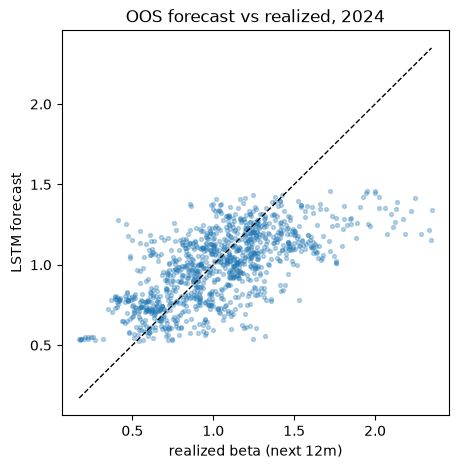

In [13]:
import matplotlib.pyplot as plt
if os.path.exists(oos_path):
    yr = pd.PeriodIndex(oos['ym'].astype(str), freq='M').year
    last = oos[yr == yr.max()]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(last['y_true'], last['yhat_lstm'], s=8, alpha=0.3)
    lim = [min(last['y_true'].min(), last['yhat_lstm'].min()),
           max(last['y_true'].max(), last['yhat_lstm'].max())]
    ax.plot(lim, lim, 'k--', lw=1)
    ax.set_xlabel('forward realized beta'); ax.set_ylabel('LSTM forecast')
    ax.set_title(f'OOS forecast vs realized, {int(yr.max())}')
    plt.show()
else:
    print('no forecasts file to plot')

## Summary

- **`features/sequences.py`** — strict 12-month lookback tensors and the 10
  rolling splits, with a discarded gap year that removes the horizon leak.
- **`features/standardize.py`** — per-month rank-standardisation plus per-fold
  DFY scaling, all leak-free.
- **`model/lstm.py`** — a small 8-unit LSTM trained on a value-weighted MSE,
  10-seed ensemble per iteration.

Full reproduction: `uv run python -m betaforecast.model.lstm`.